# Simulate digit-shaped DNA-PAINT with Picasso

Docking sites arranged as **0–9** → **Picasso Simulate** raw movie → **Picasso Localize** fitted detections.

The parameter cell below defines the acquisition; section 1 defines the docking patterns. Section 2 calls the small project helper `src/picasso_simulation.py`, which orchestrates the installed **`picasso.simulate`** and **`picasso.localize`** modules.

The default pilot has **40,000 frames**, **30 origami** (3 per digit), and a **64 × 64 pixel camera field**. Physical pixel size and timing are explicit simulation assumptions. This run enables native random orientations and incomplete docking-site incorporation (90% probability per site).

Only **`digits_locs.hdf5` and `digits_locs.yaml`** are kept under `data/simulated/digits_picasso_01/`. Ground truth and settings are embedded in the HDF5 file. The four displayed figures are also saved as PNGs in folder `outputs`.

In [10]:
from pathlib import Path
from dataclasses import asdict
from importlib.metadata import version
from io import StringIO
import json
import os
import sys

project_dir = Path.cwd().resolve()
if project_dir.name == "notebooks":
    project_dir = project_dir.parent
assert (project_dir / "src/picasso_simulation.py").is_file(), "Start in the project or notebooks folder"
os.environ.setdefault("MPLCONFIGDIR", str(project_dir / ".cache/matplotlib"))
sys.path.insert(0, str(project_dir))

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from picasso import io, lib, render, simulate
from src.picasso_simulation import (
    SimulationSettings, TESTED_VERSIONS, pattern_coordinates, run_simulation,
)

# Use Python 3.12 and requirements.txt for the tested software versions.
assert sys.version_info[:2] == (3, 12), "Use Python 3.12 for this reproducible run"
assert {name: version(name) for name in TESTED_VERSIONS} == TESTED_VERSIONS, (
    "Install the project's pinned requirements.txt before reproducing this run."
)

plt.rcdefaults()
plt.rcParams.update({"figure.dpi": 125, "font.size": 9, "axes.titlesize": 10,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})
output_dir = project_dir / "data/simulated/digits_picasso_01"
figure_dir = project_dir / "outputs/figures/simulated_digits_picasso"
figure_dir.mkdir(parents=True, exist_ok=True)

# All acquisition parameters are explicit here. Run All regenerates this output.
settings = SimulationSettings(
    frames=40000, image_size=64, particles_per_digit=3,
    spacing_nm=20.0, pixel_size_nm=130.0, integration_time_ms=100.0,
    mean_dark_ms=54054.0, mean_bright_ms=280.0,
    photon_rate_per_ms=23.0, photon_rate_std_per_ms=0.0,
    photon_budget=1500000.0, psf_sigma_px=1.06,
    background_photons_per_pixel=78.0,
    random_orientation=True,  # Native uniform 0–360° rotation, fixed for each particle.
    incorporation=0.90,        # Native per-site presence probability; 1.0 keeps every site.
    seed=20261031, box_size=7, min_net_gradient=500.0,
    example_frames=2000,  # In-memory preview; not a separate saved movie.
)
settings.validate()
display(pd.Series(asdict(settings), name="simulation setting").to_frame())
example_digit = 8  # Accumulation preview; falls back to the first supplied ID if absent.

,simulation setting
frames,40000
image_size,64
particles_per_digit,3
spacing_nm,20.0
pixel_size_nm,130.0
integration_time_ms,100.0
mean_dark_ms,54054.0
mean_bright_ms,280.0
photon_rate_per_ms,23.0
photon_rate_std_per_ms,0.0


## 1. Input patterns supplied to Picasso

**Edit `digits` below.** Each key is a nonnegative integer class ID. Each row is a string of `0` (empty) and `1` (docking site). Rows within a pattern must have equal length and at least one `1`; different patterns can have different rectangular sizes.

Change a shape, remove classes or add another integer ID. The simulator, ground truth and plots follow this dictionary automatically. Every site uses exchange label **1**, so all supplied classes share one acquisition. Spacing comes from `settings.spacing_nm`; the input panel shows the intended upright designs before random rotation and site removal.

For example, `12: ("010", "111", "010")` adds a new 3 × 3 pattern. Class IDs describe your input designs; these are not validated staple/folding designs.

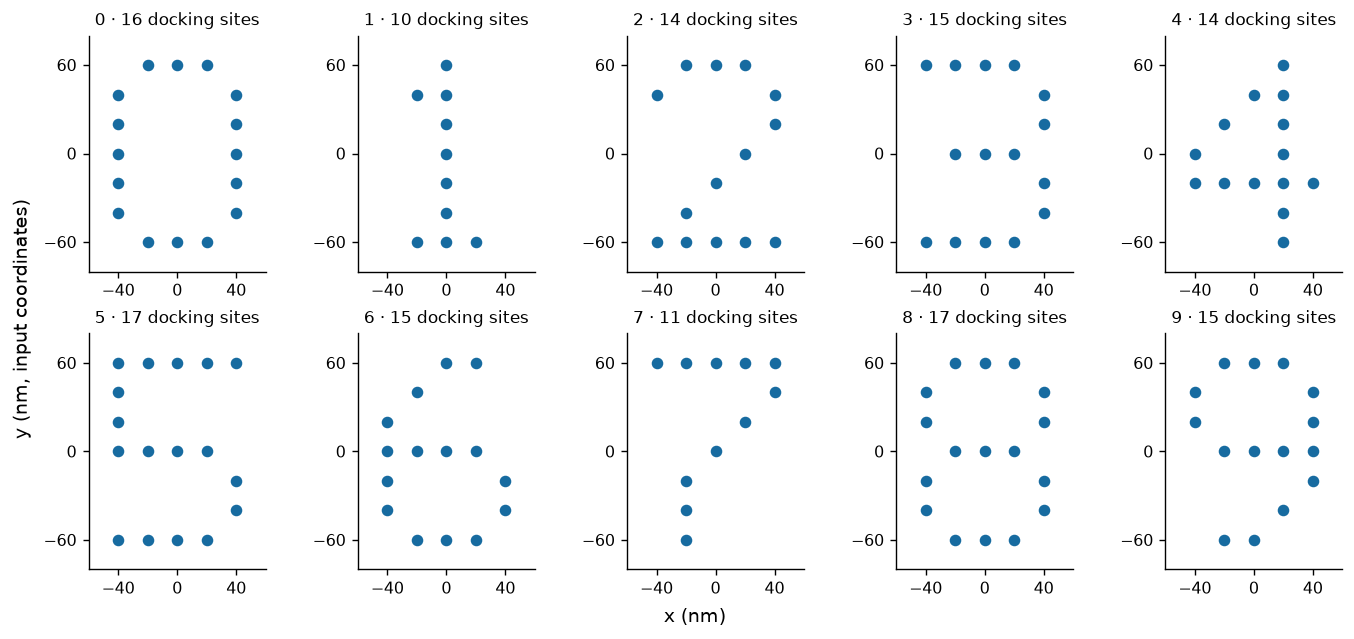

In [11]:
digits = {
    0: ('01110', '10001', '10001', '10001', '10001', '10001', '01110'),
    1: ('00100', '01100', '00100', '00100', '00100', '00100', '01110'),
    2: ('01110', '10001', '00001', '00010', '00100', '01000', '11111'),
    3: ('11110', '00001', '00001', '01110', '00001', '00001', '11110'),
    4: ('00010', '00110', '01010', '10010', '11111', '00010', '00010'),
    5: ('11111', '10000', '10000', '11110', '00001', '00001', '11110'),
    6: ('00110', '01000', '10000', '11110', '10001', '10001', '01110'),
    7: ('11111', '00001', '00010', '00100', '01000', '01000', '01000'),
    8: ('01110', '10001', '10001', '01110', '10001', '10001', '01110'),
    9: ('01110', '10001', '10001', '01111', '00001', '00010', '01100'),
}

coordinates = {digit: pattern_coordinates(rows, settings.spacing_nm) for digit, rows in digits.items()}
pattern_ids = list(digits)
if not pattern_ids:
    raise ValueError("Add at least one pattern to digits")
columns = min(5, len(digits))
rows = int(np.ceil(len(digits)/columns))
# Use common bounds that fit the largest design; default plots retain their original size.
span_x = (max(len(pattern[0]) for pattern in digits.values()) - 1) * settings.spacing_nm/2
span_y = (max(len(pattern) for pattern in digits.values()) - 1) * settings.spacing_nm/2
input_x, input_y = span_x + settings.spacing_nm, span_y + settings.spacing_nm
view_x, view_y = span_x + 1.5*settings.spacing_nm, span_y + 1.5*settings.spacing_nm
if settings.random_orientation:
    radius = max(np.linalg.norm(xy, axis=1).max() for xy in coordinates.values())
    view_x = view_y = np.ceil(radius/settings.spacing_nm)*settings.spacing_nm + 1.5*settings.spacing_nm
ticks_x = [-span_x, 0, span_x] if span_x else [0]
ticks_y = [-span_y, 0, span_y] if span_y else [0]
fig, axes = plt.subplots(rows, columns, figsize=(2.2*columns, 2.5*rows),
                         squeeze=False, constrained_layout=True)
for digit, ax in zip(pattern_ids, axes.flat):
    xy = coordinates[digit]
    ax.scatter(xy[:, 0], xy[:, 1], s=32, color="#176ba0")
    ax.set(title=f"{digit} · {len(xy)} docking sites", xlim=(-input_x, input_x),
           ylim=(-input_y, input_y), aspect="equal")
    ax.set_xticks(ticks_x)
    ax.set_yticks(ticks_y)
for ax in list(axes.flat)[len(digits):]:
    ax.set_visible(False)
fig.supxlabel("x (nm)")
fig.supylabel("y (nm, input coordinates)")
fig.savefig(figure_dir / "digit_designs.png", dpi=180)
plt.show()

## 2. Generate and localize with Picasso

This cell calls **`run_simulation(output_dir, settings, patterns=digits)`** from `src/picasso_simulation.py`. It always generates and fits a new movie using the parameters above. No known positions or labels are passed to the spot detector or fitter.

The helper validates the supplied IDs and pattern sizes, then calls the native Picasso routines in this order:

1. `defineStructure`, `generatePositions`, `rotateStructure`, `prepareStructures`: place digit patterns, rotate each particle, and retain docking sites with the chosen incorporation probability.
2. `distphotons`: simulate binding and emitted photons at each site.
3. `convertMovie`, `noisy_p`, `check_type`, `saveMovie`: generate the camera acquisition.
4. `localize.localize`: detect spots and fit their positions from that movie.

The temporary raw movie is automatically removed after localization. Its first 2,000 frames stay in memory for the preview. Only the final HDF5/YAML pair is saved. Checks verify loading and frame bounds; they do not measure classification accuracy.

**Artifact controls:** `random_orientation=True` samples one uniform 0–360° angle per particle. `incorporation=0.90` gives every designed site an independent 85% probability of being present, with the same retained/missing sites throughout the movie. This is structural site loss, distinct from stochastic blinking. Set `random_orientation=False, incorporation=1.0` to get complete baseline.

In [12]:
# This is the notebook's execution step: our helper calls native Picasso Simulate.
print(f"Native simulation module: {simulate.__file__}")
summary, preview_movie = run_simulation(output_dir, settings, patterns=digits)
display(pd.Series(summary, name="verified result").to_frame())

Native simulation module: /Users/alejandrosalgado/Desktop/DNA-origami classifier/.venv/lib/python3.12/site-packages/picasso/simulate.py
Picasso generated photon traces for 391 docking sites.
Picasso rendered 5,000/40,000 frames.
Picasso rendered 10,000/40,000 frames.
Picasso rendered 15,000/40,000 frames.
Picasso rendered 20,000/40,000 frames.
Picasso rendered 25,000/40,000 frames.
Picasso rendered 30,000/40,000 frames.
Picasso rendered 35,000/40,000 frames.
Picasso rendered 40,000/40,000 frames.
Localizing the new raw movie with Picasso Localize.
Saved 97,930 native Picasso localizations and embedded ground truth.


,verified result
engine,picasso.simulate -> raw movie -> picasso.local...
frames,40000
image_shape,"[64, 64]"
particles,30
particles_per_digit,3
random_orientation,True
incorporation_probability,0.9
requested_digits,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
detected_digits,"[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]"
designed_docking_sites,432


## 3. Read the actual fitted localizations

`digits_locs.hdf5` and its YAML are the only saved data files. Picasso reads the normal `locs` dataset. The separate `truth/` group contains particle poses/site counts, all designed sites with an `incorporated` flag, incorporated emitters, input templates and row-aligned evaluation labels.

Labels come from the known isolated particle positions; they are not classification predictions. A fit may contain photons from several docking sites and is not assigned a fabricated unique site or event.

In [13]:
locs, info = io.load_locs(str(output_dir / "digits_locs.hdf5"))
with h5py.File(output_dir / "digits_locs.hdf5") as handle:
    particles = pd.DataFrame.from_records(handle["truth/particles"][:])
    sites = pd.DataFrame.from_records(handle["truth/sites"][:])
    designed_sites = pd.DataFrame.from_records(handle["truth/designed_sites"][:])
    labels = pd.DataFrame.from_records(handle["truth/localization_labels"][:])
    assert json.loads(handle.attrs["settings_json"]) == asdict(settings)
    saved_patterns = json.loads(handle.attrs["patterns_json"])
    assert saved_patterns == {str(key): list(value) for key, value in digits.items()}
# Match the original dashboard's CSV coordinate precision without saving CSVs.
particles, sites, designed_sites = (pd.read_csv(StringIO(table.to_csv(index=False)))
                                    for table in (particles, sites, designed_sites))
assert len(locs) == len(labels) == summary["saved_localizations"]
assert np.array_equal(labels.localization_row, np.arange(len(locs)))
assert "digit" not in locs and "particle_id" not in locs
print(f"{len(locs):,} fitted detections, frames {int(locs.frame.min())}–{int(locs.frame.max())}")
display(locs.head())
counts = labels[labels.particle_id >= 0].groupby(["particle_id", "digit"]).size().rename("localizations").reset_index()
counts = particles[["particle_id", "digit"]].merge(counts, how="left").fillna({"localizations": 0})
display(counts.groupby("digit").agg(particles=("particle_id", "size"), localizations=("localizations", "sum")))
# Per-particle truth: random angles and structural site loss are explicit.
display(particles[["particle_id", "digit", "camera_orientation_degrees", "designed_sites",
                   "incorporated_sites", "missing_sites"]])

97,930 fitted detections, frames 2–39999


,frame,x,y,photons,sx,sy,bg,lpx,lpy,ellipticity,net_gradient,iterations,chi_square
0,2,5.359529,47.053322,1077.967773,1.033503,1.149866,80.205193,0.066634,0.073619,0.101197,2047.109619,4,3578.519043
1,3,5.333983,47.095047,2194.768311,1.072369,1.135537,80.679398,0.040921,0.043172,0.055629,4314.352539,3,3863.585449
2,4,5.340764,47.012623,751.406860,1.111554,1.246895,76.262589,0.098495,0.109768,0.108542,1267.798706,3,3145.979004
3,5,5.538431,26.278564,1998.357666,1.106444,1.097740,82.188385,0.045178,0.044845,0.007867,3854.032715,3,4774.659668
4,5,36.850105,36.825554,753.023560,1.042520,1.011449,78.625801,0.086038,0.083659,0.029804,1667.867310,4,4044.741943


,particles,localizations
digit,,
0,3,11541
1,3,6727
2,3,9587
3,3,9942
4,3,9008
5,3,12119
6,3,10020
7,3,7395
8,3,10954


,particle_id,digit,camera_orientation_degrees,designed_sites,incorporated_sites,missing_sites
0,0,0,30.098300,16,16,0
1,1,0,228.072541,16,16,0
2,2,0,294.144990,16,15,1
3,3,1,304.108783,10,9,1
4,4,1,357.252443,10,10,0
5,5,1,312.201028,10,8,2
6,6,2,84.068945,14,13,1
7,7,2,235.524393,14,11,3
8,8,2,75.767543,14,14,0
9,9,3,7.449188,15,12,3


## 4. Recovered digit images

One independently simulated particle per class is shown **at its simulated orientation**, without rotating it back for display. Images are rendered from **Picasso's fitted positions** and centered using ground truth only for inspection. Cyan circles mark incorporated sites; gray crosses mark designed sites that were removed. These overlays are not passed to localization or used to create the rendered images.

Titles report the camera-coordinate angle and missing-site count. A centered single-site pattern has no observable orientation, so its angle is stored as NaN. This simulation's physical calibration is assumed by construction; it does not calibrate the experimental recording.

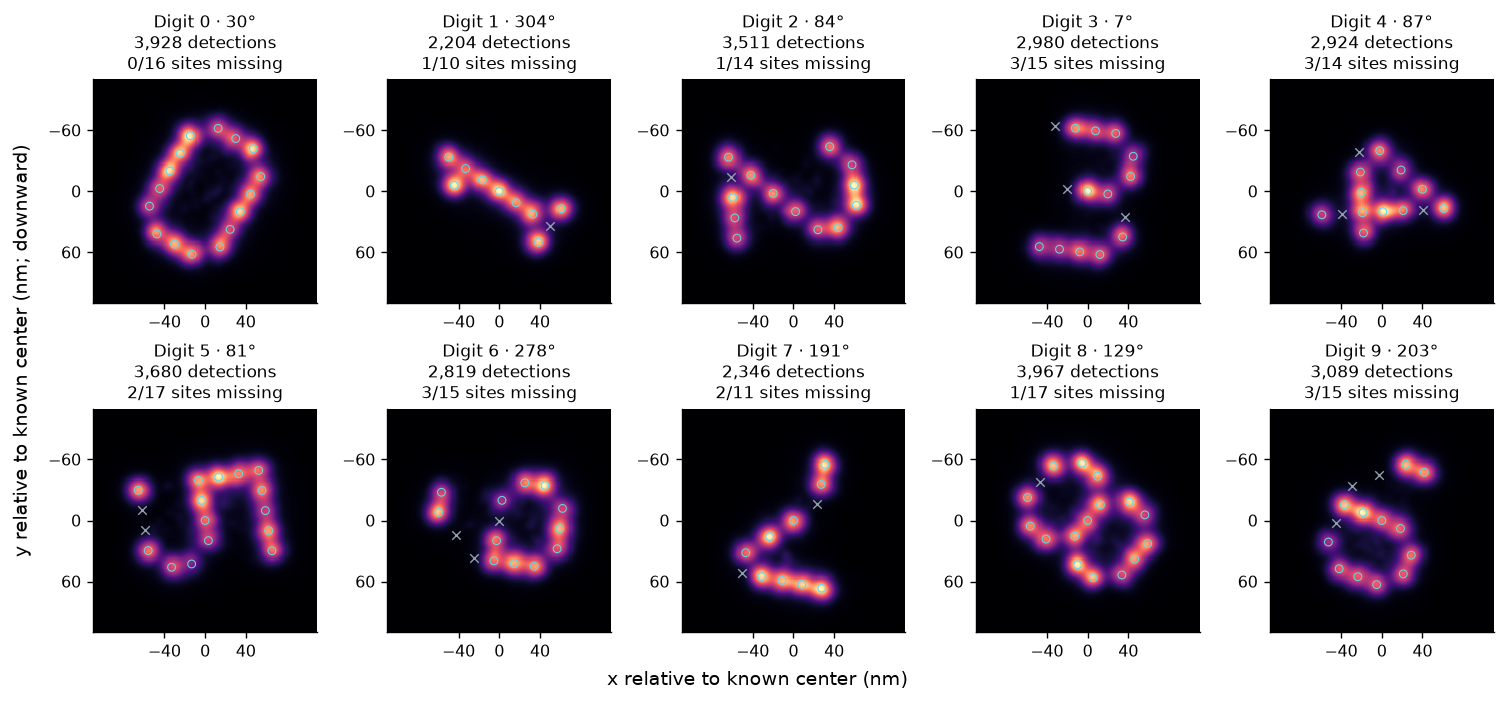

In [14]:
fig, axes = plt.subplots(rows, columns, figsize=(2.4*columns, 2.75*rows),
                         squeeze=False, constrained_layout=True)
for digit, ax in zip(pattern_ids, axes.flat):
    particle = particles[particles.digit == digit].iloc[0]
    pid = int(particle.particle_id)
    selected = locs[labels.particle_id.to_numpy() == pid]
    cx, cy = particle.camera_center_x_px, particle.camera_center_y_px
    bounds = ((cy - view_y/settings.pixel_size_nm, cx - view_x/settings.pixel_size_nm),
              (cy + view_y/settings.pixel_size_nm, cx + view_x/settings.pixel_size_nm))
    _, image = render.render(selected, info, disp_px_size=1, viewport=bounds, blur_method="gaussian")
    ax.imshow(image, origin="upper", extent=(-view_x, view_x, view_y, -view_y), cmap="magma", interpolation="nearest")
    truth_sites = sites[sites.particle_id == pid]
    ax.scatter((truth_sites.camera_x_px - cx) * settings.pixel_size_nm,
               (truth_sites.camera_y_px - cy) * settings.pixel_size_nm,
               facecolors="none", edgecolors="#63d6ef", s=20, linewidths=0.6)
    missing = designed_sites[(designed_sites.particle_id == pid) & ~designed_sites.incorporated]
    ax.scatter((missing.camera_x_px - cx) * settings.pixel_size_nm,
               (missing.camera_y_px - cy) * settings.pixel_size_nm,
               marker="x", color="#92a0aa", s=24, linewidths=0.8)
    if settings.random_orientation or settings.incorporation < 1:
        angle = particle.camera_orientation_degrees
        angle_text = f"{angle:.0f}°" if pd.notna(angle) else "rotation-invariant"
        title = f"Digit {digit} · {angle_text}\n{len(selected):,} detections\n{int(particle.missing_sites)}/{int(particle.designed_sites)} sites missing"
    else:
        title = f"Digit {digit}\n{len(selected):,} detections"
    ax.set(title=title, aspect="equal")
    ax.set_xticks(ticks_x)
    ax.set_yticks(ticks_y)
for ax in list(axes.flat)[len(digits):]:
    ax.set_visible(False)
fig.supxlabel("x relative to known center (nm)")
fig.supylabel("y relative to known center (nm; downward)")
fig.savefig(figure_dir / "recovered_digits.png", dpi=190)
plt.show()

## 5. Camera movie and accumulation over frames

A raw frame shows diffraction-limited spots; the digit emerges after accumulating fitted positions over many frames. The first 2,000 frames are kept in memory for this preview. Temporary raw movies are removed after localization, and the figures below are saved as PNGs.

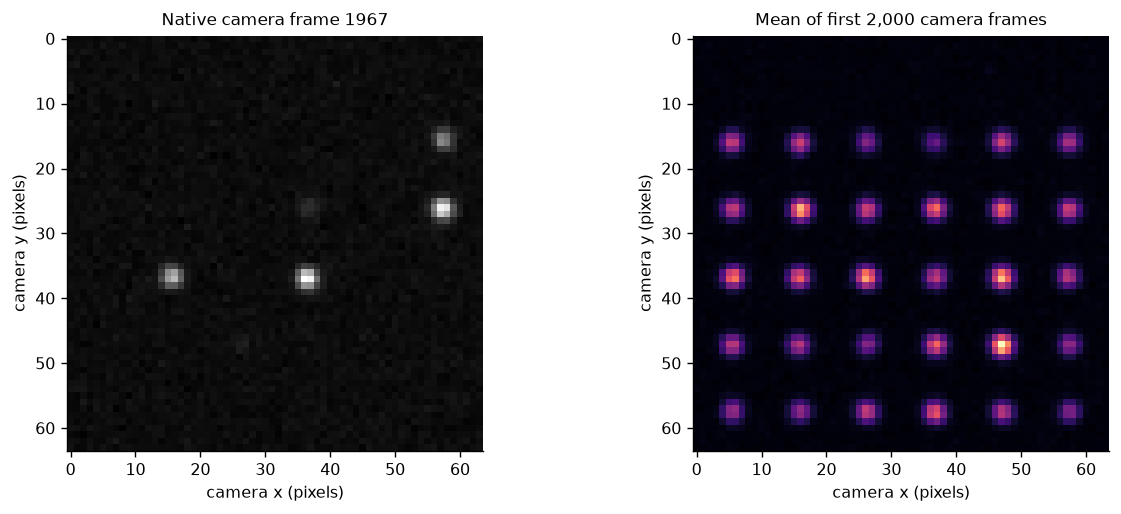

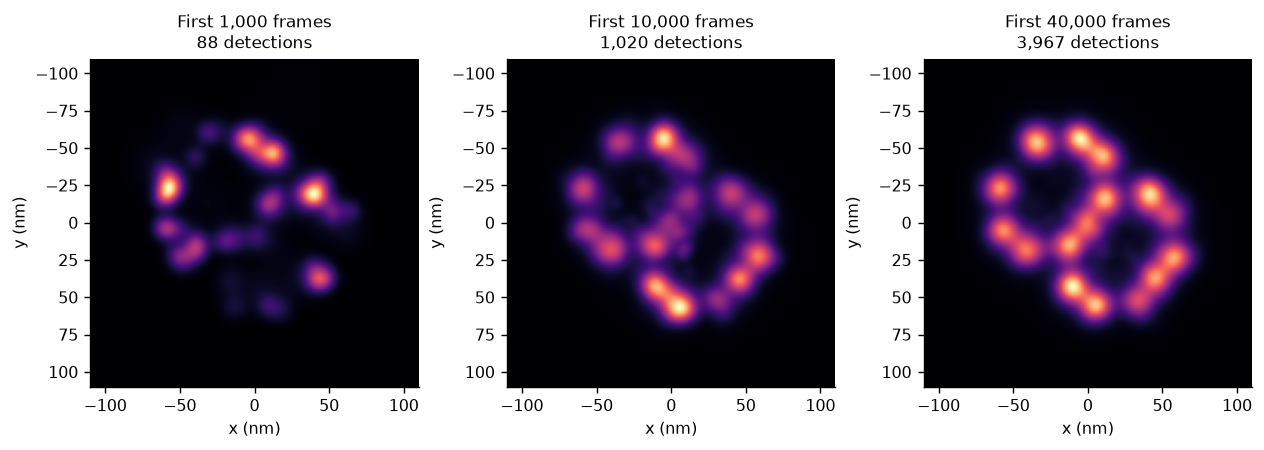

In [15]:
movie = preview_movie
bright_frame = int(np.argmax(np.asarray(movie).sum(axis=(1, 2))))
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].imshow(movie[bright_frame], cmap="gray", origin="upper")
axes[0].set_title(f"Native camera frame {bright_frame}")
axes[1].imshow(np.asarray(movie, dtype=np.float32).mean(axis=0), cmap="magma", origin="upper")
axes[1].set_title(f"Mean of first {len(movie):,} camera frames")
for ax in axes:
    ax.set(xlabel="camera x (pixels)", ylabel="camera y (pixels)")
fig.savefig(figure_dir / "movie_example.png", dpi=170)
plt.show()

preview_digit = example_digit if example_digit in digits else pattern_ids[0]
particle = particles[particles.digit == preview_digit].iloc[0]
pid = int(particle.particle_id)
selected = locs[labels.particle_id.to_numpy() == pid]
cx, cy = particle.camera_center_x_px, particle.camera_center_y_px
frame_limits = sorted({min(limit, settings.frames) for limit in (1000, 10000, settings.frames)})
fig, axes = plt.subplots(1, len(frame_limits), figsize=(10, 4), constrained_layout=True)
for limit, ax in zip(frame_limits, np.atleast_1d(axes)):
    subset = selected[selected.frame < limit]
    bounds = ((cy - view_y/settings.pixel_size_nm, cx - view_x/settings.pixel_size_nm),
              (cy + view_y/settings.pixel_size_nm, cx + view_x/settings.pixel_size_nm))
    _, image = render.render(subset, info, disp_px_size=1, viewport=bounds, blur_method="gaussian")
    ax.imshow(image, origin="upper", extent=(-view_x, view_x, view_y, -view_y), cmap="magma")
    ax.set(title=f"First {limit:,} frames\n{len(subset):,} detections", xlabel="x (nm)", ylabel="y (nm)")
fig.savefig(figure_dir / "digit_accumulation.png", dpi=170)
plt.show()

## 6. Interpretation and next use

- No input recording is needed to run this notebook.
- Random binding, photon/background noise, overlapping emission, random orientation and incomplete site incorporation are enabled in this run. Structural deformation and drift are not added. 
- Edit the pattern dictionary and acquisition parameters above, then Run All.
- The localizations and all four images are reproduced with the pinned Python 3.12 environment in `requirements.txt`.
- To inspect this dataset in notebook 01 or 02, set `data_file = project_dir / "data/simulated/digits_picasso_01/digits_locs.hdf5"`. Adjust the inspection region for the 64 × 64 field; positions are camera pixels, with the assumed 130 nm calibration in this dataset's metadata.
- Digits 6 and 9 in this input dictionary become identical under a 180° rotation.

**Method and literature:** [Schnitzbauer et al. (2017)](https://doi.org/10.1038/nprot.2017.024) Picasso. [Strauss et al. (2018)](https://doi.org/10.1038/s41467-018-04031-z) used its simulations to validate site detection on origami with variable incorporation. [Wisna et al. (2025)](https://doi.org/10.1038/s41467-025-66338-y) used Picasso Simulate for patterned origami information storage. These support the simulation approach.

The [official Simulate manual](https://picassosr.readthedocs.io/en/latest/simulate.html) accepts custom docking coordinates and generates raw movies for localization. This notebook calls the same native routines as the [Picasso 0.11.3 GUI](https://github.com/jungmannlab/picasso/blob/v0.11.3/picasso/gui/simulate.py); it supplies input coordinates and file handling, without replacing the blinking or optical model.

**Parameter origins:** 20 nm site spacing is a pilot choice also used by Strauss et al.; 130 nm pixel size, 100 ms exposure, 280 ms mean ON time and the photon budget follow Picasso GUI defaults. Mean OFF time is about 54 s. The chosen brightness (~2,300 photons/full frame), PSF sigma (1.06 pixels), and background (78 photons/pixel) approximate the recording-3 medians inspected during development. Recording-3 metadata lacks pixel size and exposure, so those remain assumptions. These rigid patterns are not a simulation of DNA folding.